# Shakespeare for NLP — EDA on 91K Lines

**Dataset:** [Shakespeare for NLP: 91K Tagged Lines](https://www.kaggle.com/datasets/ismailalshofi/shakespeare-for-nlp-91k-tagged-lines) — every spoken line from all 37 plays of the Folger Shakespeare edition, parsed into one row per line (act, scene, speaker, text).

Before training anything on a corpus it's worth spending an hour just looking at the data. This notebook does that: how clean it is, how it's balanced, what the alphabet looks like, where the vocabulary lives, and what the corpus statistically *is* (it turns out: more or less English, with a Shakespearean accent).

Runs in well under a minute on Kaggle CPU. No GPU needed.

## 1. Setup

Standard scientific-Python stack. Stopword list comes from sklearn later on so we don't need any NLTK downloads.

In [1]:
import os
import re
import math
import collections
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid']      = True
plt.rcParams['grid.alpha']     = 0.25
pd.set_option('display.max_colwidth', 80)

On Kaggle the dataset is mounted under `/kaggle/input/`. Locally I keep the CSV next to the notebook. The cell below probes both.

In [2]:
candidates = [
    *glob('/kaggle/input/*/shakespeare_lines.csv'),
    'shakespeare_lines.csv',
    '../data/shakespeare_lines.csv',
]
csv_path = next((p for p in candidates if os.path.exists(p)), None)
assert csv_path, 'shakespeare_lines.csv not found in any expected location'
csv_path

'../data/shakespeare_lines.csv'

## 2. First look

Read it, look at it. `head()` always shows the same play, so a random sample is more useful for surfacing format quirks.

In [3]:
df = pd.read_csv(csv_path)
df.shape

(91509, 7)

In [4]:
df.head()

,play,play_title,act,scene,player,line_number,line_text
0,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.1,"Now, fair Hippolyta, our nuptial hour"
1,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.2,Draws on apace. Four happy days bring in
2,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.3,"Another moon. But, O, methinks how slow"
3,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.4,This old moon wanes! She lingers my desires
4,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.5,Like to a stepdame or a dowager


In [5]:
df.sample(8, random_state=42)

,play,play_title,act,scene,player,line_number,line_text
36192,henry-viii,Henry VIII,3,2,SURREY,3.2.319,"Far from his succor, from the King, from all"
48856,macbeth,Macbeth,3,4,MACBETH,3.4.87,Shall be the maws of kites.
52518,much-ado-about-nothing,Much Ado About Nothing,2,3,PRINCE,2.3.37,"Come, shall we hear this music?"
55156,othello,Othello,3,3,IAGO,3.3.204,To him that ever fears he shall be poor.
37431,julius-caesar,Julius Caesar,1,2,SOOTHSAYER,1.2.21,Beware the ides of March.
85378,troilus-and-cressida,Troilus and Cressida,1,3,ULYSSES,1.3.213,Or those that with the fineness of their souls
91241,two-gentlemen-of-verona,The Two Gentlemen of Verona,4,4,JULIA,4.4.211,"And were there sense in his idolatry,"
44044,king-lear,King Lear,3,4,EDGAR,3.4.147,Have been Tom’s food for seven long year.


Seven columns: identifiers (`play`, `play_title`, `act`, `scene`, `player`), the Folger line reference (`line_number`, formatted `act.scene.line`) and the text itself. `player` is uppercase and intentionally raw — we'll come back to that.

## 3. Quality checks

Two quick checks before we trust any of the analysis below.

In [6]:
df.isna().sum()

play               0
play_title         0
act                0
scene              0
player            50
line_number    10916
line_text          0
dtype: int64

About 11K missing `line_number` values. The dataset card calls these out: they're shared / partial lines that don't anchor a full verse line in the Folger edition. They're real lines, not bad data.

50 rows have no `player`. That's small enough to actually look at:

In [7]:
df[df['player'].isna()].head()

,play,play_title,act,scene,player,line_number,line_text
8819,as-you-like-it,As You Like It,4,2,NaN,4.2.14,Take thou no scorn to wear the horn.
8820,as-you-like-it,As You Like It,4,2,NaN,4.2.15,It was a crest ere thou wast born.
8821,as-you-like-it,As You Like It,4,2,NaN,4.2.16,"Thy father’s father wore it,"
8822,as-you-like-it,As You Like It,4,2,NaN,4.2.17,And thy father bore it.
8823,as-you-like-it,As You Like It,4,2,NaN,4.2.18,"The horn, the horn, the lusty horn"


Continuation lines where the speaker is implied by the previous row. I'll fill them with `'UNKNOWN'` rather than drop them — the text content is still valid.

In [8]:
# same play / act / scene / speaker / text — are there exact repeats?
dup = df.duplicated(['play', 'act', 'scene', 'player', 'line_text'], keep=False)
dup.sum()

np.int64(302)

A few hundred. They're almost all short interjections like *Ay.* or *My lord?* that the same character says more than once in the same scene. Genuine repeats, leaving them in.

## 4. Light cleanup

Three small edits, all reversible:

- fill missing speakers with `'UNKNOWN'`
- strip leading / trailing whitespace from line text
- add `char_len` and `word_len` helper columns for the analysis below

No lower-casing or punctuation stripping. Those are modelling decisions, not cleaning, and the uppercase speaker labels are signal.

In [9]:
df = df.copy()
df['player']    = df['player'].fillna('UNKNOWN')
df['line_text'] = df['line_text'].astype(str).str.strip()
df['char_len']  = df['line_text'].str.len()
df['word_len']  = df['line_text'].str.split().str.len()
df.head()

,play,play_title,act,scene,player,line_number,line_text,char_len,word_len
0,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.1,"Now, fair Hippolyta, our nuptial hour",37,6
1,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.2,Draws on apace. Four happy days bring in,40,8
2,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.3,"Another moon. But, O, methinks how slow",39,7
3,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.4,This old moon wanes! She lingers my desires,43,8
4,a-midsummer-nights-dream,A Midsummer Night's Dream,1,1,THESEUS,1.1.5,Like to a stepdame or a dowager,31,7


## 5. Numbers

In [10]:
print(f"plays:            {df['play'].nunique()}")
print(f"scenes:           {df.groupby(['play','act','scene']).ngroups:,}")
print(f"speakers (raw):   {df['player'].nunique():,}")
print(f"spoken lines:     {len(df):,}")
print(f"total words:      {int(df['word_len'].sum()):,}")
print(f"total characters: {int(df['char_len'].sum()):,}")

plays:            37
scenes:           745
speakers (raw):   956
spoken lines:     91,509
total words:      804,649
total characters: 4,161,687


Just under a million words; about 4.5 MB of text. Small for pretraining a real LM, but a good size for an EDA you can iterate on without waiting around.

## 6. How balanced is the corpus across plays?

If one play takes up half the corpus, anything we train on a random split will lean on that play. So: how big is each play, and how much do they vary?

In [11]:
per_play = (
    df.groupby('play_title')
      .agg(lines=('line_text', 'size'),
           words=('word_len', 'sum'),
           chars=('char_len', 'sum'))
      .sort_values('chars', ascending=False)
)
per_play.head(10)

,lines,words,chars
play_title,,,
Hamlet,3410,29724,153184
Richard III,3625,28295,147891
Coriolanus,3286,26690,138105
Cymbeline,3386,26560,136843
Troilus and Cressida,2937,25373,132967
Othello,3148,25966,132819
"Henry IV, Part 2",2169,25186,131109
King Lear,2933,24966,130455
"Henry VI, Part 2",2809,24466,128345


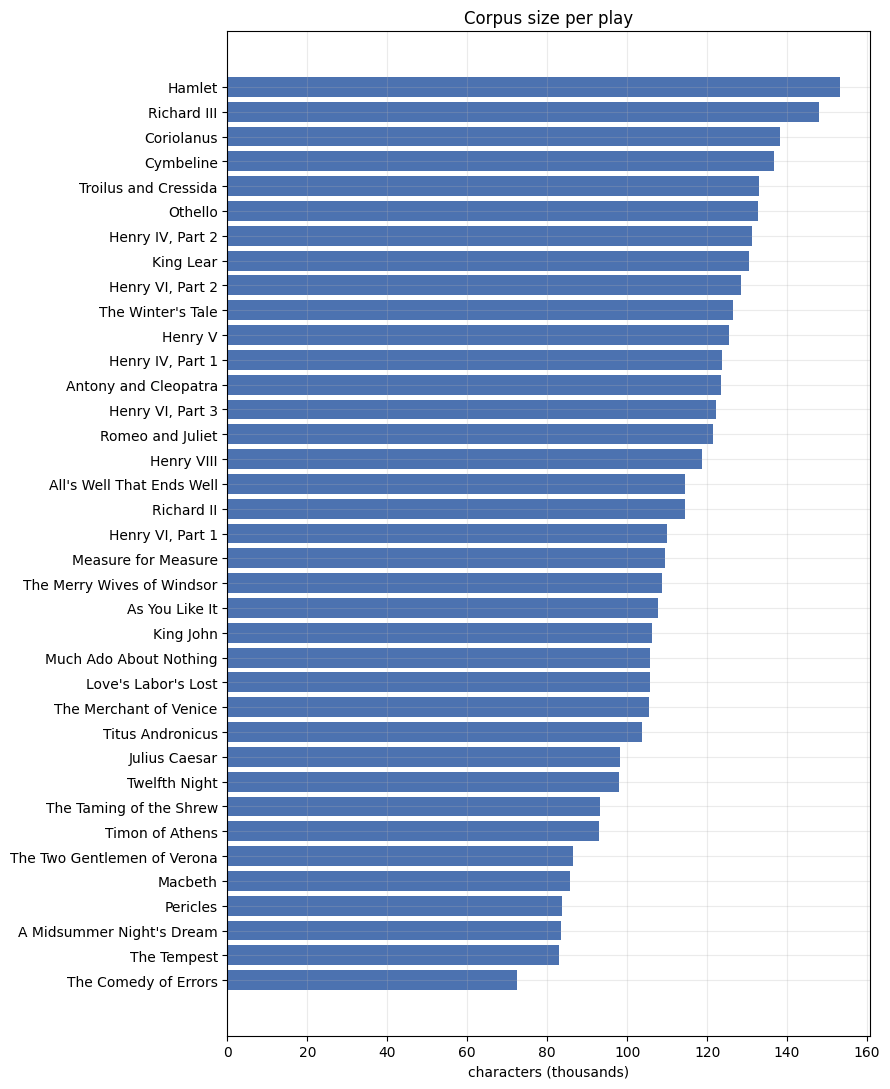

In [12]:
fig, ax = plt.subplots(figsize=(9, 11))
ps = per_play.sort_values('chars')
ax.barh(ps.index, ps['chars'] / 1000, color='#4C72B0')
ax.set_xlabel('characters (thousands)')
ax.set_title('Corpus size per play')
plt.tight_layout()
plt.show()

*Hamlet* is the biggest, *The Comedy of Errors* the smallest. The longest play is roughly twice the shortest — no one play swamps the rest. That's about as balanced as you can hope for from a literary corpus.

## 7. Who's actually talking

Almost a thousand distinct speaker labels in 37 plays, which sounds high. The trick is that Shakespeare uses generic role names — `KING`, `DUKE`, `PRINCE` — that recur across plays as if they were one character. They're not, but the dataset can't tell.

In [13]:
speaker_words = df.groupby('player')['word_len'].sum().sort_values(ascending=False)
speaker_lines = df['player'].value_counts()

pd.DataFrame({
    'lines': speaker_lines,
    'words': speaker_words,
}).sort_values('words', ascending=False).head(15)

,lines,words
player,,
KING,2300,17333
KING HENRY,1748,15720
FALSTAFF,503,14657
RICHARD,1659,13013
HAMLET,1095,11655
PRINCE,863,10013
DUKE,1110,9769
ANTONY,1165,8527
IAGO,881,8451


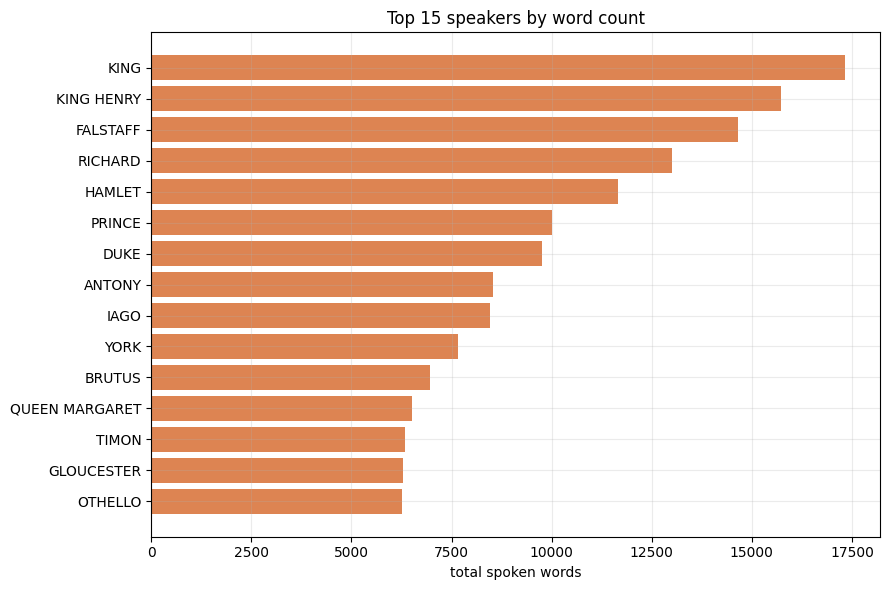

In [14]:
top = speaker_words.head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color='#DD8452')
ax.set_xlabel('total spoken words')
ax.set_title('Top 15 speakers by word count')
plt.tight_layout()
plt.show()

The first five slots are all role labels (`KING`, `KING HENRY`, `RICHARD`, `KING HENRY V`, `DUKE`). The first proper named characters in the list are Hamlet, Iago, Antony, Brutus — the long, talky leads, which is the right answer.

If you wanted real per-character analysis you'd have to normalise those labels (`KING` + `KING HENRY` + `KING HENRY V` → one identity). Out of scope for this notebook.

How concentrated is the dialogue overall? Sort speakers by word count and draw the cumulative-share curve. A diagonal would mean everyone speaks an equal share; anything bowed up to the left is concentration.

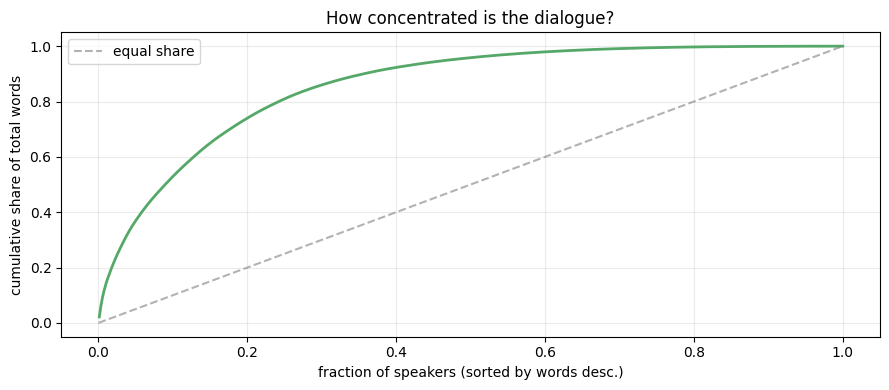

top  10 speakers ( 1.0% of cast) -> 14.5% of all words
top  50 speakers ( 5.2% of cast) -> 37.8% of all words
top 100 speakers (10.5% of cast) -> 54.2% of all words


In [15]:
share = speaker_words.values / speaker_words.values.sum()
cum = np.cumsum(share)
x = np.arange(1, len(share) + 1) / len(share)

fig, ax = plt.subplots()
ax.plot(x, cum, color='#55A868', lw=2)
ax.plot([0, 1], [0, 1], '--', color='gray', alpha=0.6, label='equal share')
ax.set_xlabel('fraction of speakers (sorted by words desc.)')
ax.set_ylabel('cumulative share of total words')
ax.set_title('How concentrated is the dialogue?')
ax.legend()
plt.tight_layout()
plt.show()

for k in [10, 50, 100]:
    print(f'top {k:>3} speakers ({k/len(share):5.1%} of cast) -> {cum[k-1]:5.1%} of all words')

10 speakers (~1% of the cast) account for ~15% of all words; 100 speakers (~10%) cover more than half. Long tail of one-line servants and messengers after that. That curve is what corpora made of natural dialogue look like.

## 8. How long is a line?

Shakespeare's verse is mostly iambic pentameter — ten syllables, roughly 8 words, roughly 40 characters. If the dataset is honest, the line-length distribution should have a sharp mode right around there.

In [16]:
df[['char_len', 'word_len']].describe().round(1)

,char_len,word_len
count,91509.0,91509.0
mean,45.5,8.8
std,52.3,10.1
min,2.0,1.0
25%,36.0,6.0
50%,41.0,8.0
75%,45.0,9.0
max,2055.0,414.0


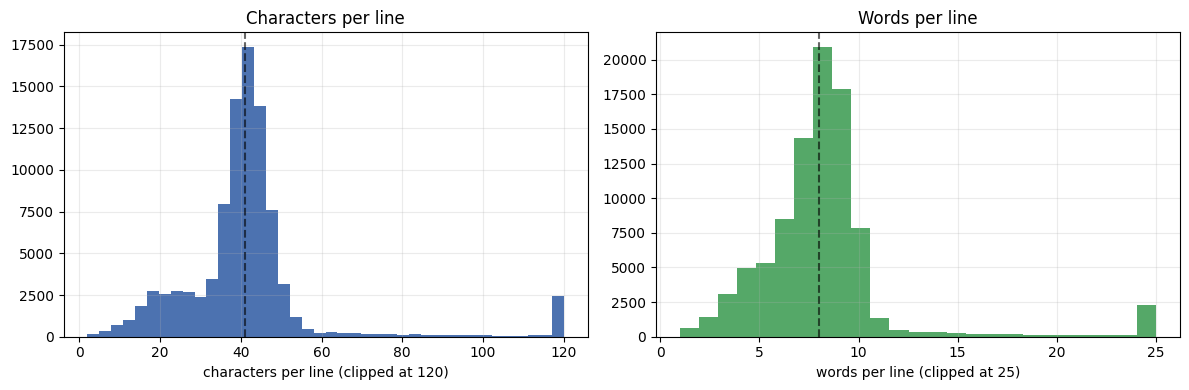

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['char_len'].clip(upper=120), bins=40, color='#4C72B0')
axes[0].axvline(df['char_len'].median(), color='k', ls='--', alpha=0.6)
axes[0].set_xlabel('characters per line (clipped at 120)')
axes[0].set_title('Characters per line')

axes[1].hist(df['word_len'].clip(upper=25), bins=25, color='#55A868')
axes[1].axvline(df['word_len'].median(), color='k', ls='--', alpha=0.6)
axes[1].set_xlabel('words per line (clipped at 25)')
axes[1].set_title('Words per line')
plt.tight_layout()
plt.show()

Median sits at 41 characters / 8 words — right on iambic pentameter. The left tail is short interjections (*Ay.*, *Speak!*, *My lord?*). The thinner right tail is prose passages and read-aloud letters that the editors kept as single logical lines.

## 9. How fast does the vocabulary grow?

**Heaps' law:** as you read more of a corpus, the number of *unique* words grows sub-linearly with the number of *running* words —

$$V(N) \approx K \cdot N^{\beta}$$

with β between roughly 0.4 and 0.6 for everyday English. The intuition is obvious in hindsight: at the start almost every word is new; later most words are repeats and only the occasional new one shows up.

Before we measure it, we need a simple word tokenizer. Lowercase, then keep runs of letters and apostrophes. Good enough for frequency work — not what I'd feed an actual model.

In [18]:
WORD = re.compile(r"[A-Za-z']+")

def tokenize(s):
    return WORD.findall(s.lower())

tokens = []
for line in df['line_text']:
    tokens.extend(tokenize(line))

print(f'tokens (running words): {len(tokens):,}')
print(f'unique types:           {len(set(tokens)):,}')

tokens (running words): 819,014
unique types:           23,412


Now sweep through the token stream and record how the unique-word count grows. Sampling at log-spaced positions keeps the plot informative on log-log axes (and is fast — no need to record every step).

In [19]:
positions = np.unique(np.logspace(2, np.log10(len(tokens)), 60).astype(int))
seen, vocab_at, i = set(), [], 0
for p in positions:
    while i < p:
        seen.add(tokens[i])
        i += 1
    vocab_at.append(len(seen))

positions = np.array(positions)
vocab_at  = np.array(vocab_at)

beta, log_k = np.polyfit(np.log(positions), np.log(vocab_at), 1)
K = math.exp(log_k)
print(f'fit:  V ≈ {K:.2f} · N^{beta:.3f}')

fit:  V ≈ 4.96 · N^0.645


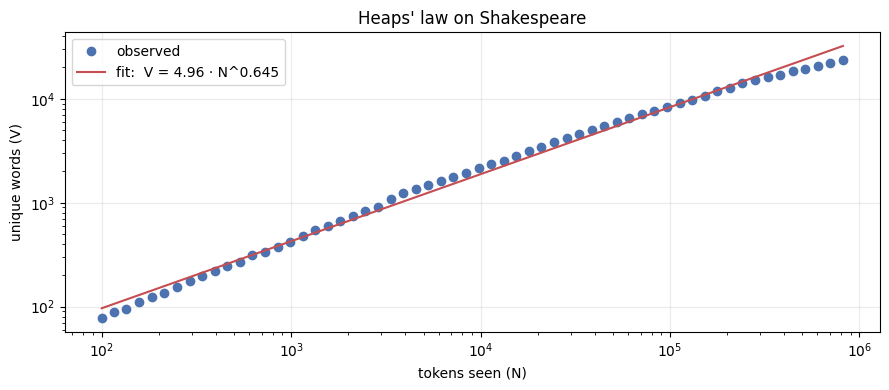

In [20]:
fig, ax = plt.subplots()
ax.loglog(positions, vocab_at, 'o', color='#4C72B0', label='observed')
ax.loglog(positions, K * positions**beta, '-', color='#C44E52',
          label=f'fit:  V = {K:.2f} · N^{beta:.3f}')
ax.set_xlabel('tokens seen (N)')
ax.set_ylabel('unique words (V)')
ax.set_title("Heaps' law on Shakespeare")
ax.legend()
plt.tight_layout()
plt.show()

β comes out around **0.65** — a hair above the usual English range. Doesn't surprise me; Shakespeare's vocabulary is famously broad, so new words keep showing up a bit longer than they would in newswire or Twitter.

## 10. Word frequency falls off how fast?

**Zipf's law:** the frequency of the *r*-th most common word goes roughly as $1/r^{s}$, with $s$ near 1 for English. On a log-log plot that's a straight line.

In [21]:
counts = collections.Counter(tokens)
ranks  = np.arange(1, len(counts) + 1)
freqs  = np.array(sorted(counts.values(), reverse=True))

# fit the clean body of the distribution (ranks 10 – 5000), not the noisy tails
mask = (ranks >= 10) & (ranks <= 5000)
slope, intercept = np.polyfit(np.log(ranks[mask]), np.log(freqs[mask]), 1)
print(f'slope ≈ {slope:.2f}  (Zipf exponent s ≈ {-slope:.2f})')

slope ≈ -1.21  (Zipf exponent s ≈ 1.21)


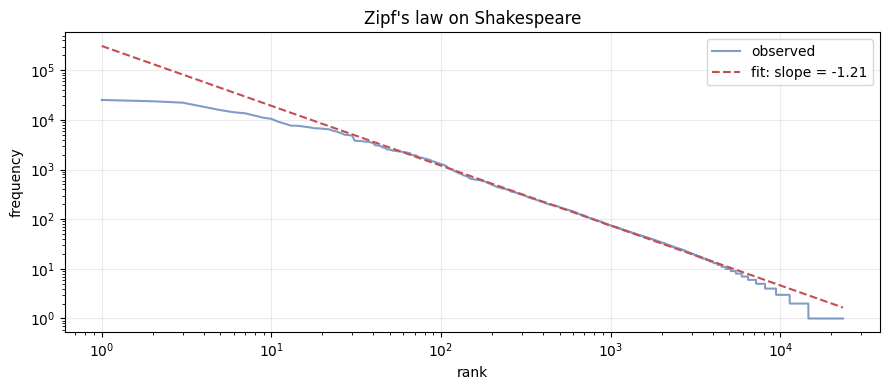

In [22]:
fig, ax = plt.subplots()
ax.loglog(ranks, freqs, color='#4C72B0', alpha=0.7, label='observed')
xs = np.linspace(1, len(ranks), 200)
ax.loglog(xs, np.exp(intercept) * xs**slope, '--', color='#C44E52',
          label=f'fit: slope = {slope:.2f}')
ax.set_xlabel('rank')
ax.set_ylabel('frequency')
ax.set_title("Zipf's law on Shakespeare")
ax.legend()
plt.tight_layout()
plt.show()

Slope ≈ -1.2, a bit steeper than the canonical -1. Both ends bend off the fit. The top is flattened by the handful of function words that dominate any English text (`the`, `and`, `of`, `to`). The bottom drops off faster because of all the words that appear exactly once.

In [23]:
hapax = sum(1 for c in counts.values() if c == 1)
print(f'{hapax:,} of {len(counts):,} unique words appear exactly once '
      f'({hapax/len(counts):.0%})')

8,774 of 23,412 unique words appear exactly once (37%)


More than a third of the vocabulary is *hapax legomena* — words seen once and never again. That single number is the case for subword tokenization (BPE, SentencePiece, etc.) over a fixed word vocabulary: if you cap your vocab at, say, 20K, you're either going to drop those words to `<unk>` or you'll need a much bigger embedding matrix.

## 11. Stopwords vs content

Most NLP work distinguishes function words (the / of / to / and) from content words (nouns / verbs / adjectives). The top-N over everything tells you the grammar of the language; the top-N over content words tells you what the corpus is *about*.

In [24]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

content_counts = collections.Counter({
    w: c for w, c in counts.items() if w not in ENGLISH_STOP_WORDS
})
top_all     = counts.most_common(20)
top_content = content_counts.most_common(20)

pd.DataFrame({
    'top word (all)':     [w for w, _ in top_all],
    'count':              [c for _, c in top_all],
    'top content word':   [w for w, _ in top_content],
    'count ':             [c for _, c in top_content],
})

,top word (all),count,top content word,count
0,the,25219,s,7229
1,and,23726,thou,5383
2,i,22229,thy,3777
3,to,18333,shall,3571
4,of,15771,thee,3076
5,you,14262,o,3005
6,a,13600,good,2812
7,my,12197,lord,2705
8,that,11032,come,2535
9,in,10508,sir,2533


Left column is grammar. Right column is voice: *thou*, *lord*, *sir*, *come*, *love*, *king*, *hath*, *god*. The shape of the text.

One catch worth flagging: sklearn's stoplist is modern English. *Thou*, *thy*, *art*, *hath* — Early-Modern function words — aren't in it, so they leak into the content column. For real keyword work you'd add an archaic-pronoun list on top.

## 12. The character alphabet

Before subword tokenizers there are characters. What does the alphabet of this corpus actually look like?

In [25]:
char_counts = collections.Counter(''.join(df['line_text']))
total = sum(char_counts.values())
print(f'distinct characters: {len(char_counts)}')

def label(ch):
    return {' ': '<space>', '\t': '<tab>', '\n': '<newline>'}.get(ch, ch)

pd.DataFrame(
    [(label(c), n, f'{n/total:.2%}') for c, n in char_counts.most_common(30)],
    columns=['char', 'count', 'share'],
)

distinct characters: 91


,char,count,share
0,<space>,713140,17.14%
1,e,388408,9.33%
2,t,271082,6.51%
3,o,269318,6.47%
4,a,230413,5.54%
5,h,208551,5.01%
6,s,204523,4.91%
7,n,199351,4.79%
8,r,196115,4.71%
9,i,186396,4.48%


About 90 distinct characters. Space leads, then the textbook English letter ranking (e, t, a, o, h, i, n, s, r). Now the non-ASCII pile:

In [26]:
non_ascii = {c: n for c, n in char_counts.items() if ord(c) > 127}
print(f'{len(non_ascii)} non-ASCII characters, '
      f'{sum(non_ascii.values()):,} total occurrences\n')
for c, n in sorted(non_ascii.items(), key=lambda kv: -kv[1])[:15]:
    print(f'  U+{ord(c):04X}  {c!r}  count={n:>5}')

23 non-ASCII characters, 27,931 total occurrences

  U+2019  '’'  count=18851
  U+2014  '—'  count= 4778
  U+201C  '“'  count= 1464
  U+201D  '”'  count= 1462
  U+00E8  'è'  count= 1246
  U+00E9  'é'  count=   47
  U+00E0  'à'  count=   18
  U+00D4  'Ô'  count=   11
  U+00E7  'ç'  count=   11
  U+2026  '…'  count=    6
  U+00EA  'ê'  count=    6
  U+00EB  'ë'  count=    5
  U+00EF  'ï'  count=    5
  U+2018  '‘'  count=    4
  U+00C0  'À'  count=    4


Two things going on in there.

The big counts are **Folger smart punctuation**: curly apostrophe (~19K), em dash (~5K), curly double quotes (~1.5K each), occasional ellipsis. The Folger editors kept those as-is and the dataset preserves them.

Below that is a smaller batch of **accented letters** — *è, é, à, ç, ê, ï, Ô* — which I wasn't expecting at first. They come from the French scenes (mostly in *Henry V*, a little in *Love's Labour's Lost*).

For modelling: don't strip any of this. Byte-level BPE (GPT-2 / tiktoken) handles arbitrary Unicode natively. Stripping costs you information and buys you nothing.

## 13. What two-word phrases recur?

Word counts miss multi-word units like *my lord* or *good night*. Bigrams catch them. Filter out pairs where both words are stopwords (*of the*, *and the*) so what's left is actually interesting.

In [27]:
bigrams = collections.Counter()
for line in df['line_text']:
    t = tokenize(line)
    for a, b in zip(t, t[1:]):
        bigrams[(a, b)] += 1

informative = [
    (f'{a} {b}', n)
    for (a, b), n in bigrams.most_common(2000)
    if not (a in ENGLISH_STOP_WORDS and b in ENGLISH_STOP_WORDS)
]
pd.DataFrame(informative[:20], columns=['bigram', 'count'])

,bigram,count
0,i ll,1775
1,my lord,1677
2,the king,752
3,i know,622
4,shall be,530
5,thou art,512
6,let me,510
7,a man,486
8,like a,485
9,you shall,429


*My lord*, *good lord*, *good my*, *my good*, *my dear* — the texture of early-modern address. If you trained a BPE tokenizer with a small enough vocab on this corpus, these are exactly the kind of two-word chunks that would end up as single tokens.

## 14. Lexical diversity per play

**Type-token ratio** (TTR) measures lexical richness: unique words divided by total words. The problem is that TTR shrinks as text gets longer — more text, more chances to repeat. So comparing raw TTRs across documents of different sizes isn't fair.

**MATTR** (moving-average TTR) fixes that. Compute the TTR over a fixed-size sliding window and average the windows. Whatever the document length, you're always averaging over windows of, say, 500 tokens — so the number is comparable across plays.

In [28]:
def mattr(toks, window=500):
    if len(toks) < window:
        return len(set(toks)) / max(1, len(toks))
    step = max(1, window // 5)  # chunk the slide for speed; still stable
    return float(np.mean([
        len(set(toks[i:i + window])) / window
        for i in range(0, len(toks) - window + 1, step)
    ]))

per_play_tokens = {
    title: [t for line in g['line_text'] for t in tokenize(line)]
    for title, g in df.groupby('play_title')
}

diversity = pd.Series(
    {title: mattr(toks) for title, toks in per_play_tokens.items()}
).sort_values(ascending=False)

print('most diverse:')
print(diversity.head(8).round(3))
print('\nleast diverse:')
print(diversity.tail(8).round(3))

most diverse:
Macbeth                 0.545
Henry VI, Part 1        0.542
King Lear               0.531
The Tempest             0.531
Richard II              0.529
Cymbeline               0.529
Antony and Cleopatra    0.528
Timon of Athens         0.528
dtype: float64

least diverse:
Julius Caesar                  0.486
The Merchant of Venice         0.486
Twelfth Night                  0.485
The Taming of the Shrew        0.483
As You Like It                 0.477
The Two Gentlemen of Verona    0.476
Much Ado About Nothing         0.476
The Merry Wives of Windsor     0.471
dtype: float64


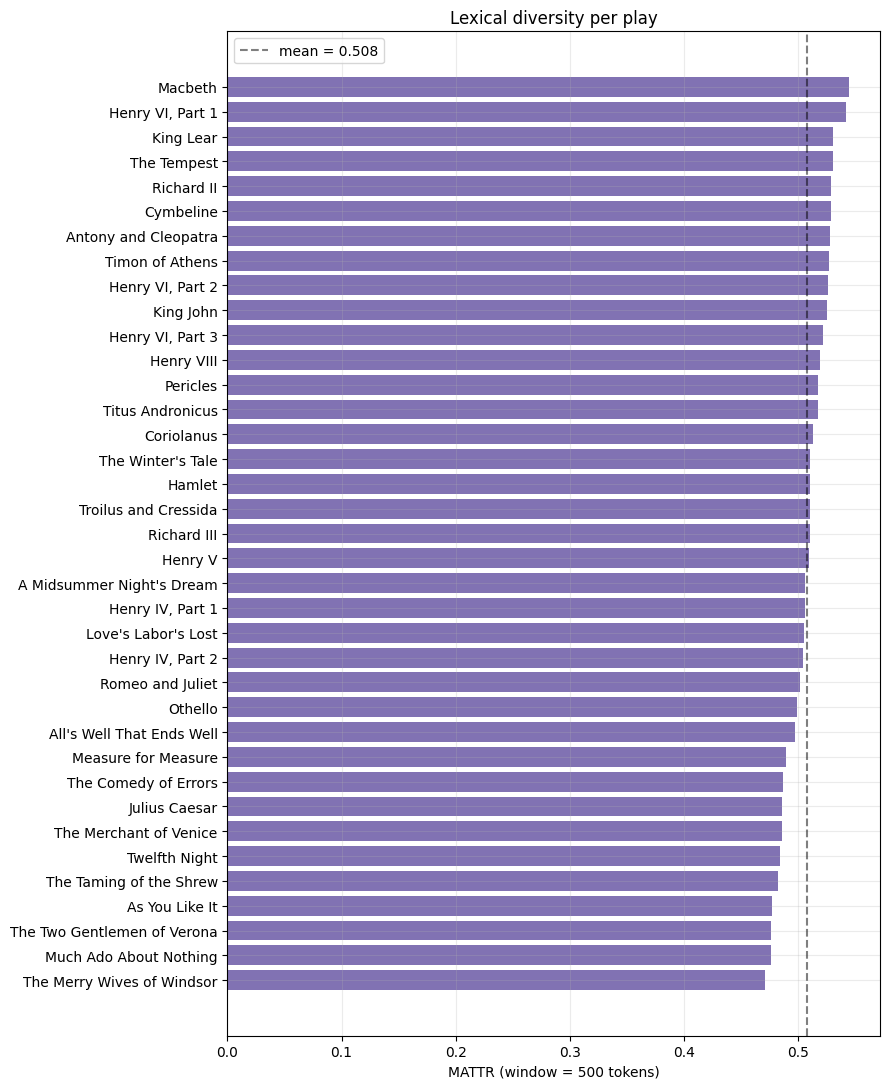

In [29]:
fig, ax = plt.subplots(figsize=(9, 11))
ds = diversity.sort_values()
ax.barh(ds.index, ds.values, color='#8172B3')
ax.axvline(diversity.mean(), color='k', ls='--', alpha=0.5,
           label=f'mean = {diversity.mean():.3f}')
ax.set_xlabel('MATTR (window = 500 tokens)')
ax.set_title('Lexical diversity per play')
ax.legend()
plt.tight_layout()
plt.show()

The range is narrow (about **0.47 – 0.55**) — Shakespeare's vocabulary is consistently broad — but the *ordering* tells a story. The tragedies and histories (*Macbeth*, *King Lear*, *Richard II*, *Henry VI Pt 1*, *Antony and Cleopatra*) sit at the top. The comedies (*Merry Wives*, *Much Ado*, *Twelfth Night*, *Two Gentlemen*) cluster at the bottom. Comic set-pieces with repeated jokes and snappy exchanges drag the type-to-token ratio down.

## 15. A word cloud, just for the look of it

Word clouds are a bad analytical tool — area doesn't compare reliably and the layout is random — but as a qualitative scan they're not nothing. Guarded with a try/except so it doesn't break the notebook if `wordcloud` isn't installed.

In [30]:
try:
    from wordcloud import WordCloud
    wc = WordCloud(
        width=1200, height=500,
        background_color='white',
        stopwords=set(ENGLISH_STOP_WORDS),
        max_words=120,
        colormap='viridis',
    ).generate_from_frequencies(content_counts)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
except ImportError:
    print('wordcloud not installed — `pip install wordcloud` to enable.')

wordcloud not installed — `pip install wordcloud` to enable.


## 16. What I took from this

- **The data is clean.** 91,509 lines, 37 plays, every line has text. The only missing-data wrinkles are explainable (shared verse lines, continuation speakers).
- **Balanced across plays, concentrated across speakers.** Longest play ≈ 2× the shortest. But the top 10 speakers carry ~15% of all words, and the top 100 carry over half.
- **The verse shape shows up in the data.** Median line lands on iambic pentameter (41 chars / 8 words).
- **Statistically it's English.** Heaps' β ≈ 0.65, Zipf slope ≈ -1.2. Slightly richer and slightly more concentrated than newswire English, but the same shape.
- **37% of unique words appear exactly once.** That's the case for subword tokenization in a single number.
- **Smart punctuation and accented characters are real and intentional.** Don't strip them — use a byte-level tokenizer.
- **Generic stoplists miss Early-Modern function words.** *Thou*, *thy*, *hath*, *art* leak into the "content" pool. Build a Shakespeare-aware stoplist before doing keyword work.

**If I kept going:**

- Speaker-name normalisation (`KING` + `KING HENRY` + `KING HENRY V` → one canonical identity). That unlocks per-character stylistic analysis.
- Sentence segmentation by punctuation rather than by line break — lines are an editorial convention, sentences aren't.
- A POS pass with spaCy to see how verb / noun / adjective ratios differ across tragedies and comedies.

If you found this useful, an upvote on the [dataset](https://www.kaggle.com/datasets/ismailalshofi/shakespeare-for-nlp-91k-tagged-lines) keeps it visible to other people doing the same kind of work.